<a href="https://colab.research.google.com/github/vivekpandey0706/Mini_GPT/blob/main/Mini_GPT_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini GPT

A small character-level GPT built from scratch in PyTorch and trained on Tiny Shakespeare (about 1.1M characters).
6 layers, 6 attention heads, 384-dim embeddings, 256 characters of context, 10.8M parameters.

It gets to about 1.48 validation loss (nats per character). A bigram baseline gets 2.48.

Needs a GPU (Runtime -> Change runtime type -> T4). Takes 30-40 minutes end to end.

## Data
Tiny Shakespeare is one text file of Shakespeare's plays. Every character is a token (65 of them). First 90% for training, last 10% for validation.

In [ ]:
!wget -q https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

In [ ]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
use_mixed_precision = device == "cuda"
print("running on", device)


def autocast():

    return torch.autocast(device_type=device, dtype=torch.float16 if device =="cuda" else torch.bfloat16,
                          enabled=use_mixed_precision)

running on cuda


In [ ]:
with open("input.txt", encoding="utf-8") as file:
    text = file.read()

characters = sorted(set(text))
vocab_size = len(characters)
char_to_index ={char: index for  index, char in enumerate(characters)}
index_to_char ={index: char for index, char  in enumerate(characters)}


def encode(string):
    return [char_to_index[char] for char in string]

def decode(indices):
    return "".join(index_to_char[index] for index in indices)


data = torch.tensor(encode(text), dtype=torch.long)
split_point = int(0.9 * len(data))
train_data, val_data = data[:split_point], data[split_point:]

print(f"{len(text):,} characters, vocabulary of {vocab_size}")
print(repr("".join(characters)))
print(f"train {len(train_data):,}, validation {len(val_data):,}")
print(encode("hii there"), "->", repr(decode(encode("hii there"))))
# expected: 1,115,394 characters, vocabulary of 65
#           train 1,003,854, validation 111,540
#           [46, 47, 47, 1, 58, 46, 43, 56, 43] -> 'hii there'

1,115,394 characters, vocabulary of 65
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
train 1,003,854, validation 111,540
[46, 47, 47, 1, 58, 46, 43, 56, 43] -> 'hii there'


## Batches
Random 256-character chunks. The targets are the same chunk shifted by one, so every chunk is 256 training examples at once.

In [ ]:
def get_batch(split, batch_size, context_length):
    #targets are the same windows shifted one character to the right
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - context_length, (batch_size,))
    inputs = torch.stack([source[start:start + context_length] for start in starts])
    targets = torch.stack([source[start + 1:start + context_length + 1] for start in starts])
    return inputs.to(device), targets.to(device)


inputs, targets = get_batch("train", batch_size=4, context_length=8)
print(inputs.shape, targets.shape)
print("targets = inputs shifted by one:", torch.equal(inputs[:, 1:], targets[:, :-1]))

for t in range(8):
    context = decode(inputs[0, :t + 1].tolist())
    print(f"given {context!r:14} -> predict {decode([targets[0, t].item()])!r}")

torch.Size([4, 8]) torch.Size([4, 8])
targets = inputs shifted by one: True
given 'L'            -> predict 'e'
given 'Le'           -> predict 't'
given 'Let'          -> predict "'"
given "Let'"         -> predict 's'
given "Let's"        -> predict ' '
given "Let's "       -> predict 'h'
given "Let's h"      -> predict 'e'
given "Let's he"     -> predict 'a'


## Measuring loss
One batch is too noisy to compare models, so losses are averaged over a lot of random batches.

In [ ]:
@torch.no_grad()
def estimate_loss(model, batch_size, context_length, eval_batches=200):
    # a single batch is too noisy to compare models, so we will take average of 200 random batches per split.
    model.eval()
    averages = {}
    for split in ["train", "val"]:
        batch_losses = torch.zeros(eval_batches)
        for i in range(eval_batches):
            inputs, targets = get_batch(split, batch_size, context_length)
            with autocast():
                _, loss = model(inputs, targets)
            batch_losses[i] = loss.item()
        averages[split] = batch_losses.mean().item()
    model.train()
    return averages

## Baselines
The numbers to beat. One bigram built by counting, and the same bigram learned as a 65x65 table. Both only look at the previous character.

In [ ]:
# the number to beat, part 1: a bigram built by counting, like Project bigram trigram name generator
bigram_counts = torch.zeros((vocab_size, vocab_size))
bigram_counts.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
bigram_probs = (bigram_counts + 0.1) / (bigram_counts + 0.1).sum(dim=1, keepdim=True)
counting_val_loss = -bigram_probs[val_data[:-1], val_data[1:]].log().double().mean().item()
print(f"counting bigram, validation NLL {counting_val_loss:.4f}")   # 2.4838


# the number to beat, part 2: the same bigram as a tiny neural network
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.next_char_logits = nn.Embedding(vocab_size, vocab_size)   # row i = scores for whatever follows char i

    def forward(self, indices, targets=None):
        logits = self.next_char_logits(indices)                        # logits is batch, time, vocab
        if targets is None:
            return logits, None
        batch, time_steps, vocab = logits.shape
        loss = F.cross_entropy(logits.view(batch * time_steps, vocab), targets.view(batch * time_steps))
        return logits, loss


bigram_model = BigramLanguageModel(vocab_size).to(device)
optimizer = torch.optim.AdamW(bigram_model.parameters(), lr=1e-2)
for step in range(5000):
    inputs, targets = get_batch("train", batch_size=32, context_length=8)
    _, loss = bigram_model(inputs, targets)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

bigram_losses = estimate_loss(bigram_model, batch_size=32, context_length=8)

print(f"neural bigram: train {bigram_losses['train']:.4f}, val {bigram_losses['val']:.4f}")   # should be about 2.48-2.50

start_token = torch.zeros((1, 1), dtype=torch.long, device=device)   # index 0 is the newline character
generated = start_token
for _ in range(200):
    probabilities = F.softmax(bigram_model(generated)[0][:, -1, :], dim=-1)
    generated = torch.cat([generated, torch.multinomial(probabilities, num_samples=1)], dim=1)
print(decode(generated[0].tolist()))   # Shakespeare's letters and spacing, but hardly any real words

counting bigram, validation NLL 2.4838
neural bigram: train 2.4581, val 2.4760



CExthy brid owindake on, bth

HAPet bube d e.
S:
O:
IS:
Falatanss:
Wanthar u qur, vet?
F dilasoate awice my.

Hastarom oroup
Yowhthetof isth ble mil ndill, ath iree sengmin lat Hetidrovets, and Win 


## Building blocks
- One attention head: queries, keys, values, scaled scores, and a causal mask so nothing sees the future.
- Multi-head attention: 6 heads side by side, concatenated and mixed by a linear layer.
- Feed-forward: each position thinks about what it gathered (384 -> 1536 -> 384).
- Transformer block: LayerNorm before each part, residual connection around each part.

The use_* switches are only there for the ablation further down.

In [ ]:
class SelfAttentionHead(nn.Module):
    # one head of causal self attention
    def __init__(self, embedding_size, head_size, context_length, dropout):
        super().__init__()
        self.key = nn.Linear(embedding_size, head_size, bias=False)
        self.query = nn.Linear(embedding_size, head_size, bias=False)
        self.value = nn.Linear(embedding_size, head_size, bias=False)
        # lower triangular mask
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_length, context_length)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch, time_steps, _ = x.shape
        keys = self.key(x)        # (batch, time, head_size) --> this is what each position offers
        queries = self.query(x)   # (batch, time, head_size) -> this is what each position is looking for
        # match every query against every key, and also scaled by 1/sqrt(head_size) so the softmax doesn't saturate
        scores = queries @ keys.transpose(-2, -1) * keys.shape[-1] ** -0.5           # (batch, time, time)
        future = self.causal_mask[:time_steps, :time_steps] == 0
        scores = scores.masked_fill(future, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ self.value(x)                                               # returns in -> (batch, time, head_size)


class MultiHeadAttention(nn.Module):
    # several heads side by side-->  their outputs are concatenated and mixed by one linear layer
    def __init__(self, num_heads, embedding_size, context_length, dropout):
        super().__init__()
        head_size = embedding_size // num_heads
        self.heads = nn.ModuleList(
            [SelfAttentionHead(embedding_size, head_size, context_length, dropout) for _ in range(num_heads)]
        )
        self.projection = nn.Linear(head_size * num_heads, embedding_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        combined = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.projection(combined))


class FeedForward(nn.Module):
    # every position processes what it gathered, on its own widen 4x, ReLU, narrow back
    def __init__(self, embedding_size, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(embedding_size, 4 * embedding_size),
            nn.ReLU(),
            nn.Linear(4 * embedding_size, embedding_size),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.layers(x)


class TransformerBlock(nn.Module):
    # communication (attention) then computation (feed forward), each wrapped in pre LayerNorm and a residual.

    def __init__(self, embedding_size, num_heads, context_length, dropout,
                 use_residual=True, use_layer_norm=True, use_feed_forward=True):
        super().__init__()
        self.attention = MultiHeadAttention(num_heads, embedding_size, context_length, dropout)
        self.feed_forward = FeedForward(embedding_size, dropout)
        self.norm_before_attention = nn.LayerNorm(embedding_size)
        self.norm_before_feed_forward = nn.LayerNorm(embedding_size)
        self.use_residual = use_residual
        self.use_layer_norm = use_layer_norm
        self.use_feed_forward = use_feed_forward

    def forward(self, x):
        attention_input = self.norm_before_attention(x) if self.use_layer_norm else x
        attended = self.attention(attention_input)
        x = x + attended if self.use_residual else attended

        if self.use_feed_forward:
            feed_forward_input = self.norm_before_feed_forward(x) if self.use_layer_norm else x
            processed = self.feed_forward(feed_forward_input)

            x = x + processed if self.use_residual else processed
        return x

## The model
Token + position embeddings, 6 blocks, final LayerNorm, linear layer to 65 logits. Weights start small (std 0.02, like GPT-2). `generate` samples one character at a time, with optional temperature and top-k.

In [ ]:
class GPTLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_size=384, num_heads=6, num_layers=6, context_length=256,
                 dropout=0.2, use_residual=True, use_layer_norm=True, use_feed_forward=True):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_size)
        self.position_embedding = nn.Embedding(context_length, embedding_size)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_size, num_heads, context_length, dropout,
                             use_residual, use_layer_norm, use_feed_forward)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(embedding_size) if use_layer_norm else nn.Identity()
        self.output_head = nn.Linear(embedding_size, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        #untrained model starts close to uniform guessing
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def forward(self, indices, targets=None):
        batch, time_steps = indices.shape
        positions = torch.arange(time_steps, device=indices.device)
        x = self.token_embedding(indices) + self.position_embedding(positions)   # (batch, time, embedding)
        x = self.final_norm(self.blocks(x))
        logits = self.output_head(x)                                             # (batch, time, vocab)
        if targets is None:
            return logits, None
        loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, indices, new_tokens, temperature=1.0, top_k=None):
        for _ in range(new_tokens):
            recent = indices[:, -self.context_length:]   # position embeddings only go up to max context_length
            logits, _ = self(recent)
            logits = logits[:, -1, :].float() / temperature   # only the last position will predict the next character
            if top_k is not None:
                kth_best = torch.topk(logits, top_k).values[:, [-1]]
                logits = logits.masked_fill(logits < kth_best, float("-inf"))
            probabilities = F.softmax(logits, dim=-1)
            next_index = torch.multinomial(probabilities, num_samples=1)
            indices = torch.cat([indices, next_index], dim=1)
        return indices

## Checks before training
Worth doing before burning GPU time:
- the parameter count should be 10,788,929
- the untrained loss should be about ln(65) = 4.17
- changing character 100 shouldn't change any earlier prediction (proves the mask works)

In [ ]:
check_model = GPTLanguageModel(vocab_size).to(device)
print(f"{sum(p.numel() for p in check_model.parameters()):,} parameters")   # 10,788,929

check_model.eval()   # dropout off,so the comparisons below are exact
inputs, targets = get_batch("train", batch_size=4, context_length=256)
with torch.no_grad():
    logits, loss = check_model(inputs, targets)
print(tuple(logits.shape), f"untrained loss {loss.item():.3f} vs ln 65 = {math.log(vocab_size):.3f}")
# (4, 256, 65), untrained loss is about 4.17 to4.20

# causality test: changing character 100 must not change any prediction before it
altered = inputs.clone()
altered[:, 100] = (altered[:, 100] + 1) % vocab_size
with torch.no_grad():
    original_logits, _ = check_model(inputs)
    altered_logits, _ = check_model(altered)
print("predictions 0-99 unchanged:", torch.allclose(original_logits[:, :100], altered_logits[:, :100], atol=1e-5))   # True
print("predictions from 100 on changed:", not torch.allclose(original_logits[:, 100:], altered_logits[:, 100:], atol=1e-5))   # True
del check_model

10,788,929 parameters
(4, 256, 65) untrained loss 4.248 vs ln 65 = 4.174
predictions 0-99 unchanged: True
predictions from 100 on changed: True


## Ablation
Tiny models (32-dim, 8-character context, 5,000 steps each), adding one piece at a time, to see what actually helps.

In [ ]:
# What each piece buys-> small models (width 32, context 8), each trained for 5,000 steps
ablation_ladder = [
    ("one attention head", dict(num_heads=1, num_layers=1, use_feed_forward=False, use_residual=False, use_layer_norm=False)),
    ("four heads", dict(num_heads=4, num_layers=1, use_feed_forward=False, use_residual=False, use_layer_norm=False)),
    ("+ feed-forward", dict(num_heads=4, num_layers=1, use_feed_forward=True, use_residual=False, use_layer_norm=False)),
    ("3 blocks + residuals", dict(num_heads=4, num_layers=3, use_feed_forward=True, use_residual=True, use_layer_norm=False)),
    ("+ LayerNorm", dict(num_heads=4, num_layers=3, use_feed_forward=True, use_residual=True, use_layer_norm=True)),
]

ablation_results = {"bigram": bigram_losses["val"]}
for name, options in ablation_ladder:
    torch.manual_seed(1337)
    small_model = GPTLanguageModel(vocab_size, embedding_size=32, context_length=8, dropout=0.0, **options).to(device)
    optimizer = torch.optim.AdamW(small_model.parameters(), lr=1e-3)
    for step in range(5000):
        inputs, targets = get_batch("train", batch_size=32, context_length=8)
        _, loss = small_model(inputs, targets)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    ablation_results[name] = estimate_loss(small_model, batch_size=32, context_length=8)["val"]
    print(f"{name:22s} val {ablation_results[name]:.4f}")
# roughly: 2.4, 2.3, 2.25, 2.1, 2.05; each step should beat the one before (small changes in values is noise)

one attention head     val 2.5873
four heads             val 2.4543
+ feed-forward         val 2.6092
3 blocks + residuals   val 2.2580
+ LayerNorm            val 2.0555


## Training the real model
AdamW at 3e-4, batches of 64 x 256, 5,000 steps, dropout 0.2, mixed precision. Losses are checked every 500 steps, and a checkpoint is saved each time in case Colab disconnects.

In [ ]:
# The real model: 6 layers, 6 heads of 64, width 384, context 256.
batch_size = 64
context_length = 256
max_steps = 5000
eval_every = 500
learning_rate = 3e-4

torch.manual_seed(1337)
model = GPTLanguageModel(vocab_size, context_length=context_length).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
scaler = torch.amp.GradScaler("cuda", enabled=use_mixed_precision)   # stops small float16 gradients rounding to 0

history = []   # (step, train loss, val loss)
start = time.time()
for step in range(max_steps + 1):
    if step % eval_every == 0:
        losses = estimate_loss(model, batch_size, context_length, eval_batches=100)   # 1.6M characters per split is plenty
        history.append((step, losses["train"], losses["val"]))
        print(f"step {step:>5}   train {losses['train']:.4f}   val {losses['val']:.4f}   ({(time.time() - start) / 60:.1f} min)")
        torch.save(model.state_dict(), "gpt_shakespeare.pt")   # a checkpoint, in case Colab disconnects
    if step == max_steps:
        break

    inputs, targets = get_batch("train", batch_size, context_length)
    with autocast():
        _, loss = model(inputs, targets)
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
# expected: about 4.2 at step 0, below the bigram's 2.48 within the first 500 steps,
#ending around 1.48 on validation (train ends lower: the model is starting to memorise)

step     0   train 4.2217   val 4.2311   (0.2 min)
step   500   train 1.7501   val 1.9065   (2.5 min)
step  1000   train 1.3927   val 1.6204   (4.7 min)
step  1500   train 1.2646   val 1.5309   (7.0 min)
step  2000   train 1.1891   val 1.5022   (9.2 min)
step  2500   train 1.1254   val 1.4988   (11.5 min)
step  3000   train 1.0700   val 1.4877   (13.7 min)
step  3500   train 1.0122   val 1.4921   (15.9 min)
step  4000   train 0.9601   val 1.4979   (18.2 min)
step  4500   train 0.9076   val 1.5326   (20.4 min)
step  5000   train 0.8511   val 1.5632   (22.7 min)


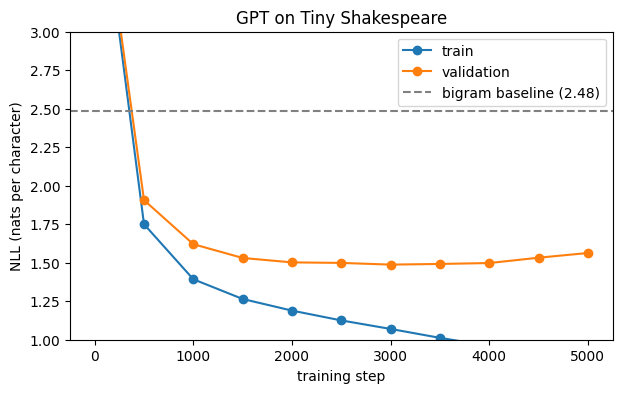

In [ ]:
steps_logged = [step for step, _, _ in history]
plt.figure(figsize=(7, 4))
plt.plot(steps_logged, [train for _, train, _ in history], marker="o", label="train")
plt.plot(steps_logged, [val for _, _, val in history], marker="o", label="validation")
plt.axhline(counting_val_loss, color="gray", linestyle="--", label=f"bigram baseline ({counting_val_loss:.2f})")
plt.ylim(1.0, 3.0)
plt.xlabel("training step")
plt.ylabel("NLL (nats per character)")
plt.title("GPT on Tiny Shakespeare")
plt.legend()
plt.savefig("gpt_training_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Generating text
Starting from a single newline. Low temperature plays it safe and repeats itself; high temperature gets creative and starts misspelling.

In [ ]:
model.eval()
start_token = torch.zeros((1, 1), dtype=torch.long, device=device)
sample = decode(model.generate(start_token, new_tokens=1000)[0].tolist())
print(sample)
with open("generated_shakespeare.txt", "w", encoding="utf-8") as file:
    file.write(sample)


for temperature in [0.5, 1.0, 1.5]:
    text_sample = decode(model.generate(start_token, new_tokens=300, temperature=temperature)[0].tolist())
    print(f"\ntemperature {temperature}\n{text_sample}")
# low temperature-> plays safe and repeats itself . high temperature gets creative and misspells.


The tribunes of the hours o' the fielding.
Here's come; and that do lose him;
The unaccustom of his house, you my foot
To receive Henry and yours, as well appointed
With all his, his duty suppliants, or exoral
And on postertation of his king:
How shall we please your secondred with him?

KING RICHARD III:
To meet the king! God, and what stay hath now!
Your wife to give the keys, whose both you may mean:
Sleep the young Norfolk after'd like a sea,
And not like a miserable swue
That pass'd me in the public of the king.

Second Murderer:
An eagle, at villain.

First Murderer:
Though I thought, my liege.

Second Murderer:
How now, my lord, some other return me.

MAMILLIUS:
Now, by my life, I say this?

First Murderer:
If it be never spoke a fardel thing,
at your honour's disturb into the world.

Second Murderer:
What?

MENENIUS:
We must stab he,
Which therefore we start for this centurion,
No sequence. Even yet you to such a present name
Be cursed with unstrucking them! We'll not think up

## Results
Validation loss, bits per character (loss / ln 2) and perplexity (e^loss) for every model.

In [ ]:
final_step, final_train_loss, final_val_loss = history[-1]
gpt_parameters = sum(p.numel() for p in model.parameters())

print(" Model | Parameters | Validation NLL | Bits per character | Perplexity |")

for name, parameters, loss in [
    ("Bigram, counting", vocab_size * vocab_size, counting_val_loss),
    ("Bigram, neural", vocab_size * vocab_size, bigram_losses["val"]),
    ("GPT, 6 layers x 6 heads", gpt_parameters, final_val_loss),
]:
    print(f"| {name} | {parameters:,} | {loss:.3f} | {loss / math.log(2):.2f} | {math.exp(loss):.1f} |")
# expected roughly: bigram 2.48 (3.58 bits, perplexity 11.9), GPT about 1.48 (2.14 bits, perplexity 4.4)

 Model | Parameters | Validation NLL | Bits per character | Perplexity |
| Bigram, counting | 4,225 | 2.484 | 3.58 | 12.0 |
| Bigram, neural | 4,225 | 2.476 | 3.57 | 11.9 |
| GPT, 6 layers x 6 heads | 10,788,929 | 1.563 | 2.26 | 4.8 |
